In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

FILE_PATH = Path("FMCG_Real_World_Data_Analyst_Practice.xlsx")

# If the workbook is stored elsewhere, replace FILE_PATH with its full path.
xls = pd.ExcelFile(FILE_PATH)
print("Workbook sheets:", xls.sheet_names)

sales_raw = pd.read_excel(FILE_PATH, sheet_name="Raw_Sales")
products_raw = pd.read_excel(FILE_PATH, sheet_name="Product_Master")
customers_raw = pd.read_excel(FILE_PATH, sheet_name="Customer_Master")
inventory_raw = pd.read_excel(FILE_PATH, sheet_name="Inventory_Data")

print("Raw sales:", sales_raw.shape)
print("Product master:", products_raw.shape)
print("Customer master:", customers_raw.shape)
print("Inventory:", inventory_raw.shape)


Workbook sheets: ['START_HERE', 'Raw_Sales', 'Product_Master', 'Customer_Master', 'Inventory_Data', 'Cleaning_Tasks', 'Data_Dictionary', 'Analyst_Workflow']
Raw sales: (614, 19)
Product master: (23, 6)
Customer master: (61, 7)
Inventory: (88, 8)


In [5]:
def profile_table(df, table_name):
    report = pd.DataFrame({
        "Column": df.columns,
        "Data_Type": [str(df[c].dtype) for c in df.columns],
        "Missing_Count": [df[c].isna().sum() for c in df.columns],
        "Missing_%": [(df[c].isna().mean() * 100).round(2) for c in df.columns],
        "Unique_Values": [df[c].nunique(dropna=True) for c in df.columns]
    })
    print(f"\\n{table_name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    display(report)

profile_table(sales_raw, "Raw_Sales")
profile_table(products_raw, "Product_Master")
profile_table(customers_raw, "Customer_Master")
profile_table(inventory_raw, "Inventory_Data")

print("Exact duplicate sales rows:", sales_raw.duplicated().sum())
print("Repeated Order_ID rows:", sales_raw["Order_ID"].duplicated(keep=False).sum())
print("Unique Order_ID values:", sales_raw["Order_ID"].nunique())


\nRaw_Sales: 614 rows × 19 columns


,Column,Data_Type,Missing_Count,Missing_%,Unique_Values
0,Order_ID,str,0,0.00,591
1,Order_Date,object,2,0.33,354
2,Customer_ID,str,41,6.68,63
3,Region,str,0,0.00,19
4,City,str,15,2.44,20
5,Product_ID,str,0,0.00,26
6,Product_Name,str,10,1.63,30
7,Category,str,0,0.00,18
8,Brand,str,0,0.00,21
9,Quantity,object,27,4.40,78


\nProduct_Master: 23 rows × 6 columns


,Column,Data_Type,Missing_Count,Missing_%,Unique_Values
0,Product_ID,str,0,0.0,23
1,Product_Name,str,0,0.0,23
2,Category,str,0,0.0,7
3,Brand,str,0,0.0,16
4,Unit_Price,object,0,0.0,21
5,Unit_Cost,float64,0,0.0,18


\nCustomer_Master: 61 rows × 7 columns


,Column,Data_Type,Missing_Count,Missing_%,Unique_Values
0,Customer_ID,str,0,0.0,61
1,Customer_Name,str,0,0.0,61
2,Customer_Type,str,0,0.0,9
3,Region,str,0,0.0,8
4,City,str,0,0.0,12
5,Loyalty_Tier,str,0,0.0,7
6,Join_Date,object,0,0.0,59


\nInventory_Data: 88 rows × 8 columns


,Column,Data_Type,Missing_Count,Missing_%,Unique_Values
0,Product_ID,str,0,0.0,22
1,Product_Name,str,0,0.0,22
2,Warehouse,str,0,0.0,7
3,Region,str,0,0.0,8
4,Stock_On_Hand,int64,0,0.0,82
5,Reorder_Level,int64,0,0.0,85
6,Max_Stock,int64,0,0.0,88
7,Last_Stock_Update,object,0,0.0,24


Exact duplicate sales rows: 8
Repeated Order_ID rows: 46
Unique Order_ID values: 591


In [6]:
# Work on copies so the raw imported tables remain unchanged.
sales = sales_raw.copy()
products = products_raw.copy()
customers = customers_raw.copy()
inventory = inventory_raw.copy()

# Remove only fully identical transaction rows.
sales = sales.drop_duplicates().copy()

def clean_text(series):
    return series.astype("string").str.strip().replace({"": pd.NA})

def title_case(series):
    return clean_text(series).str.title()

# Standardize identifier fields.
for df, cols in [
    (sales, ["Order_ID", "Customer_ID", "Product_ID"]),
    (products, ["Product_ID"]),
    (customers, ["Customer_ID"]),
    (inventory, ["Product_ID"])
]:
    for col in cols:
        df[col] = clean_text(df[col]).str.upper()

# Standardize region aliases.
region_map = {
    "N": "North", "NRTH": "North", "NORTH": "North",
    "S": "South", "SOUTH": "South",
    "E": "East", "EAST": "East",
    "W": "West", "WEST": "West", "WESTT": "West"
}
def standardize_region(s):
    x = clean_text(s).str.upper()
    return x.map(region_map).fillna(x.str.title())

for df in [sales, customers, inventory]:
    df["Region"] = standardize_region(df["Region"])

# Standardize cities and correct only the clear spelling variant in this workbook.
city_map = {
    "DELHI": "Delhi", "MUMBAI": "Mumbai", "KOLKATA": "Kolkata",
    "CHENNAI": "Chennai", "BENGALURU": "Bengaluru",
    "HYDERABAD": "Hyderabad", "HYDRABAD": "Hyderabad",
    "AHMEDABAD": "Ahmedabad", "BHUBANESWAR": "Bhubaneswar",
    "PATNA": "Patna", "LUCKNOW": "Lucknow", "PUNE": "Pune",
    "CHANDIGARH": "Chandigarh"
}
for df in [sales, customers]:
    city = clean_text(df["City"]).str.upper()
    df["City"] = city.map(city_map).fillna(city.str.title())

# Standardize other categorical text.
for col in ["Category", "Brand", "Product_Name"]:
    sales[col] = title_case(sales[col])
for col in ["Category", "Brand", "Product_Name"]:
    products[col] = title_case(products[col])

sales["Sales_Channel"] = title_case(sales["Sales_Channel"])
sales["Sales_Channel"] = sales["Sales_Channel"].replace({
    "Distributer": "Distributor"
})
sales["Payment_Method"] = title_case(sales["Payment_Method"])
sales["Payment_Method"] = sales["Payment_Method"].replace({
    "Credit Card": "Card"
})
sales["Order_Status"] = clean_text(sales["Order_Status"]).str.lower().str.title()
sales["Order_Status"] = sales["Order_Status"].replace({
    "Canceled": "Cancelled", "In Transit": "In Transit"
})
customers["Customer_Type"] = title_case(customers["Customer_Type"]).replace({
    "Super Market": "Supermarket"
})
customers["Loyalty_Tier"] = title_case(customers["Loyalty_Tier"])

# Parse mixed date formats.
for df, col in [
    (sales, "Order_Date"),
    (customers, "Join_Date"),
    (inventory, "Last_Stock_Update")
]:
    df[col] = pd.to_datetime(df[col], errors="coerce", format="mixed")

# Convert numeric columns, removing currency symbols and separators.
def to_number(series):
    cleaned = (series.astype("string")
               .str.replace(r"[$,]", "", regex=True)
               .str.replace(r"\\s", "", regex=True))
    return pd.to_numeric(cleaned, errors="coerce")

for col in ["Quantity", "Unit_Price", "Sales_Amount", "Cost_Amount", "Profit"]:
    sales[col] = to_number(sales[col])

for col in ["Unit_Price", "Unit_Cost"]:
    products[col] = to_number(products[col])

for col in ["Stock_On_Hand", "Reorder_Level", "Max_Stock"]:
    inventory[col] = to_number(inventory[col])

# Normalize discounts: 10, 10%, and 0.10 all mean 10%.
discount_text = clean_text(sales["Discount_Pct"])
has_percent = discount_text.str.contains("%", na=False)
discount_num = pd.to_numeric(
    discount_text.str.replace("%", "", regex=False), errors="coerce"
).astype(float)
has_percent = has_percent.fillna(False).astype(bool)
sales["Discount_Pct"] = np.where(
    has_percent, discount_num / 100,
    np.where(discount_num > 1, discount_num / 100, discount_num)
)
sales["Discount_Invalid_Flag"] = (
    sales["Discount_Pct"].isna() |
    ~sales["Discount_Pct"].between(0, 1)
)
sales.loc[sales["Discount_Invalid_Flag"], "Discount_Pct"] = np.nan

# Normalize Returned values without assuming that unusual codes are valid.
returned_map = {
    "0": 0, "0.0": 0, "NO": 0, "N": 0, "FALSE": 0,
    "1": 1, "1.0": 1, "YES": 1, "Y": 1, "TRUE": 1
}
sales["Returned_Binary"] = (
    clean_text(sales["Returned"]).str.upper().map(returned_map)
)
sales["Returned_Invalid_Flag"] = sales["Returned_Binary"].isna()

# Quality flags.
sales["Quantity_Invalid_Flag"] = sales["Quantity"].isna() | (sales["Quantity"] <= 0)
sales["Unit_Price_Invalid_Flag"] = sales["Unit_Price"].isna() | (sales["Unit_Price"] <= 0)
sales["Order_Date_Invalid_Flag"] = sales["Order_Date"].isna()
products["Master_Unit_Price_Invalid_Flag"] = products["Unit_Price"].isna() | (products["Unit_Price"] <= 0)
products["Unit_Cost_Invalid_Flag"] = products["Unit_Cost"].isna() | (products["Unit_Cost"] <= 0)

print("Cleaned sales shape:", sales.shape)
print("Exact duplicate rows removed:", len(sales_raw) - len(sales))
print("Invalid quantity rows:", sales["Quantity_Invalid_Flag"].sum())
print("Invalid discount rows:", sales["Discount_Invalid_Flag"].sum()) 
print("Invalid returned values:", sales["Returned_Invalid_Flag"].sum())
print("Invalid order dates:", sales["Order_Date_Invalid_Flag"].sum())


Cleaned sales shape: (606, 25)
Exact duplicate rows removed: 8
Invalid quantity rows: 48
Invalid discount rows: 39
Invalid returned values: 4
Invalid order dates: 5


In [7]:
sales.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City', 'Product_ID',
       'Product_Name', 'Category', 'Brand', 'Quantity', 'Unit_Price',
       'Discount_Pct', 'Sales_Channel', 'Payment_Method', 'Returned',
       'Order_Status', 'Sales_Amount', 'Cost_Amount', 'Profit',
       'Discount_Invalid_Flag', 'Returned_Binary', 'Returned_Invalid_Flag',
       'Quantity_Invalid_Flag', 'Unit_Price_Invalid_Flag',
       'Order_Date_Invalid_Flag'],
      dtype='str')

In [8]:
products.columns

Index(['Product_ID', 'Product_Name', 'Category', 'Brand', 'Unit_Price',
       'Unit_Cost', 'Master_Unit_Price_Invalid_Flag',
       'Unit_Cost_Invalid_Flag'],
      dtype='str')

In [9]:
# Check master-key uniqueness and foreign-key coverage.
print("Duplicate Product_ID in product master:", products["Product_ID"].duplicated().sum())
print("Duplicate Customer_ID in customer master:", customers["Customer_ID"].duplicated().sum())

product_ids = set(products["Product_ID"].dropna())
customer_ids = set(customers["Customer_ID"].dropna())

sales["Product_Key_Missing_Flag"] = ~sales["Product_ID"].isin(product_ids)
sales["Customer_Key_Missing_Flag"] = sales["Customer_ID"].isna() | ~sales["Customer_ID"].isin(customer_ids)

# Check date logic and unusual order status / category values.
sales["Future_Order_Date_Flag"] = sales["Order_Date"] > pd.Timestamp.today().normalize()
sales["Known_Order_Status_Flag"] = sales["Order_Status"].isin(
    ["Delivered", "Cancelled", "Returned", "In Transit", "Pending"]
)

quality_summary = pd.DataFrame({
    "Issue": [
        "Exact duplicate rows removed",
        "Repeated Order_ID rows (may be multi-line orders)",
        "Missing customer IDs",
        "Customer IDs not found in master",
        "Product IDs not found in master",
        "Invalid quantity",
        "Invalid sales unit price",
        "Invalid discount",
        "Invalid Returned value",
        "Unparseable order date",
        "Unrecognized order status"
    ],
    "Rows": [
        sales_raw.duplicated().sum(),
        sales["Order_ID"].duplicated(keep=False).sum(),
        sales["Customer_ID"].isna().sum(),
        sales["Customer_Key_Missing_Flag"].sum(),
        sales["Product_Key_Missing_Flag"].sum(),
        sales["Quantity_Invalid_Flag"].sum(),
        sales["Unit_Price_Invalid_Flag"].sum(),
        sales["Discount_Invalid_Flag"].sum(),
        sales["Returned_Invalid_Flag"].sum(),
        sales["Order_Date_Invalid_Flag"].sum(),
        (~sales["Known_Order_Status_Flag"]).sum()
    ]
})
display(quality_summary)

# Review invalid values before deciding whether to exclude them.
display(sales.loc[
    sales["Quantity_Invalid_Flag"] | sales["Discount_Invalid_Flag"] |
    sales["Returned_Invalid_Flag"] | sales["Order_Date_Invalid_Flag"],
    ["Order_ID", "Order_Date", "Quantity", "Discount_Pct", "Returned",
     "Order_Status", "Quantity_Invalid_Flag", "Discount_Invalid_Flag",
     "Returned_Invalid_Flag", "Order_Date_Invalid_Flag"]
].head(20))


Duplicate Product_ID in product master: 0
Duplicate Customer_ID in customer master: 0


,Issue,Rows
0,Exact duplicate rows removed,8
1,Repeated Order_ID rows (may be multi-line orders),30
2,Missing customer IDs,40
3,Customer IDs not found in master,42
4,Product IDs not found in master,5
5,Invalid quantity,48
6,Invalid sales unit price,12
7,Invalid discount,39
8,Invalid Returned value,4
9,Unparseable order date,5


,Order_ID,Order_Date,Quantity,Discount_Pct,Returned,Order_Status,Quantity_Invalid_Flag,Discount_Invalid_Flag,Returned_Invalid_Flag,Order_Date_Invalid_Flag
8,ORD10481,2024-02-06,34,NaN,0,Delivered,False,True,False,False
16,ORD10253,2024-08-04,<NA>,0.05,0,Delivered,True,False,False,False
18,ORD10167,2024-10-20,55,NaN,0,Delivered,False,True,False,False
22,ORD10453,2024-12-05,<NA>,0.10,0,Delivered,True,False,False,False
39,ORD10358,2024-09-17,30,NaN,0,Delivered,False,True,False,False
50,ORD10480,2024-12-24,24,0.10,2,Cancelled,False,False,True,False
54,ORD10014,2024-06-29,-5,NaN,0,Delivered,True,True,False,False
72,ORD10236,2024-12-12,41,NaN,0,Delivered,False,True,False,False
84,ORD10102,2024-05-09,<NA>,0.00,0,Delivered,True,False,False,False
92,ORD10370,2024-01-13,4,NaN,0,Delivered,False,True,False,False


In [10]:
sales.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Product_ID,Product_Name,Category,Brand,Quantity,...,Discount_Invalid_Flag,Returned_Binary,Returned_Invalid_Flag,Quantity_Invalid_Flag,Unit_Price_Invalid_Flag,Order_Date_Invalid_Flag,Product_Key_Missing_Flag,Customer_Key_Missing_Flag,Future_Order_Date_Flag,Known_Order_Status_Flag
0,ORD10278,2024-04-19,C018,East,Kolkata,P009,Masala Instant Noodles,Noodles,Quickbowl,200,...,False,0.0,False,False,False,False,False,False,False,True
1,ORD10361,2024-03-12,C007,South,Bengaluru,P014,Potato Chips 100G,Snacks,Crispybite,60,...,False,0.0,False,False,False,False,False,False,False,True
2,ORD10482,2024-02-05,C014,South,Kolkata,P018,Basmati Rice 5Kg,Cooking Essentials,Goldharvest,38,...,False,0.0,False,False,False,False,False,False,False,True
3,ORD10323,2024-10-18,C039,South,Chennai,P021,Beauty Soap 100G,Beverages,Silkycare,500,...,False,0.0,False,False,False,False,False,False,False,True
4,ORD10547,2024-12-03,C037,West,Ahmedabad,P001,Cola 500Ml,Beverages,Freshfizz,49,...,False,0.0,False,False,False,False,False,False,False,True


In [11]:

sales.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City', 'Product_ID',
       'Product_Name', 'Category', 'Brand', 'Quantity', 'Unit_Price',
       'Discount_Pct', 'Sales_Channel', 'Payment_Method', 'Returned',
       'Order_Status', 'Sales_Amount', 'Cost_Amount', 'Profit',
       'Discount_Invalid_Flag', 'Returned_Binary', 'Returned_Invalid_Flag',
       'Quantity_Invalid_Flag', 'Unit_Price_Invalid_Flag',
       'Order_Date_Invalid_Flag', 'Product_Key_Missing_Flag',
       'Customer_Key_Missing_Flag', 'Future_Order_Date_Flag',
       'Known_Order_Status_Flag'],
      dtype='str')

In [12]:
# Ensure master keys are unique before joining.
products = products.drop_duplicates(subset="Product_ID", keep="first")
customers = customers.drop_duplicates(subset="Customer_ID", keep="first")

fact = sales.merge(
    products[["Product_ID", "Product_Name", "Category", "Brand", "Unit_Cost",
              "Master_Unit_Price_Invalid_Flag", "Unit_Cost_Invalid_Flag"]],
    on="Product_ID", how="left", suffixes=("", "_Master"), validate="many_to_one"
)
fact = fact.merge(
    customers[["Customer_ID", "Customer_Type", "Loyalty_Tier",
               "Join_Date", "Region", "City"]],
    on="Customer_ID", how="left", suffixes=("", "_Customer"),
    validate="many_to_one"
)

# Compare transaction product descriptors with the master, then use master labels when matched.
for col in ["Product_Name", "Category", "Brand"]:
    fact[f"{col}_Mismatch_Flag"] = (
        fact[col].notna() & fact[f"{col}_Master"].notna() &
        fact[col].astype("string").str.casefold().ne(
            fact[f"{col}_Master"].astype("string").str.casefold()
        )
    )
    fact[col] = fact[f"{col}_Master"].combine_first(fact[col])

# Preserve transaction geography; customer-master geography is available for comparison.
fact["Sales_Amount_Calc"] = (
    fact["Quantity"] * fact["Unit_Price"] * (1 - fact["Discount_Pct"])
)
fact["Cost_Amount_Calc"] = (
    fact["Quantity"] * fact["Unit_Cost"].where(fact["Unit_Cost"].gt(0))
)

fact["Sales_Amount_Used_Fallback_Flag"] = fact["Sales_Amount_Calc"].isna()
fact["Cost_Amount_Used_Fallback_Flag"] = fact["Cost_Amount_Calc"].isna()

fact["Sales_Amount_Final"] = fact["Sales_Amount_Calc"].fillna(fact["Sales_Amount"])
fact["Cost_Amount_Final"] = fact["Cost_Amount_Calc"].fillna(fact["Cost_Amount"])
fact["Profit_Final"] = fact["Sales_Amount_Final"] - fact["Cost_Amount_Final"]
fact["Profit_Final"] = fact["Profit_Final"].fillna(fact["Profit"])

# Status and return treatment.
fact["Is_Returned"] = (
    fact["Returned_Binary"].eq(1) |
    fact["Order_Status"].eq("Returned")
)
fact["Is_Cancelled"] = fact["Order_Status"].eq("Cancelled")
fact["Is_Delivered"] = fact["Order_Status"].eq("Delivered")
fact["Is_Recognized"] = (
    fact["Is_Delivered"] & ~fact["Is_Returned"] &
    fact["Quantity"].gt(0) & fact["Order_Date"].notna()
)

fact["Recognized_Revenue"] = fact["Sales_Amount_Final"].where(fact["Is_Recognized"], 0)
fact["Recognized_Cost"] = fact["Cost_Amount_Final"].where(fact["Is_Recognized"], 0)
fact["Recognized_Profit"] = fact["Profit_Final"].where(fact["Is_Recognized"], 0)
fact["Recognized_Quantity"] = fact["Quantity"].where(fact["Is_Recognized"], 0)

# Audit: compare calculated amounts with reported amounts when both exist.
fact["Sales_Amount_Variance"] = fact["Sales_Amount"] - fact["Sales_Amount_Calc"]
fact["Cost_Amount_Variance"] = fact["Cost_Amount"] - fact["Cost_Amount_Calc"]

print("Analysis-ready fact table:", fact.shape)
print("Recognized sales lines:", fact["Is_Recognized"].sum())
print("Unmatched customer keys:", fact["Customer_Key_Missing_Flag"].sum())
print("Unmatched product keys:", fact["Product_Key_Missing_Flag"].sum())
display(fact.head())


Analysis-ready fact table: (606, 60)
Recognized sales lines: 450
Unmatched customer keys: 42
Unmatched product keys: 5


,Order_ID,Order_Date,Customer_ID,Region,City,Product_ID,Product_Name,Category,Brand,Quantity,...,Is_Returned,Is_Cancelled,Is_Delivered,Is_Recognized,Recognized_Revenue,Recognized_Cost,Recognized_Profit,Recognized_Quantity,Sales_Amount_Variance,Cost_Amount_Variance
0,ORD10278,2024-04-19,C018,East,Kolkata,P009,Masala Instant Noodles,Noodles,Quickbowl,200,...,False,False,True,True,81.0,60.0,21.0,200,0.0,0.0
1,ORD10361,2024-03-12,C007,South,Bengaluru,P014,Potato Chips 100G,Snacks,Crispybite,60,...,False,False,True,True,57.0,37.2,19.8,60,0.0,0.0
2,ORD10482,2024-02-05,C014,South,Kolkata,P018,Basmati Rice 5Kg,Cooking Essentials,Goldharvest,38,...,False,True,False,False,0.0,0.0,0.0,0,0.0,0.0
3,ORD10323,2024-10-18,C039,South,Chennai,P021,Beauty Soap 100G,Personal Care,Silkycare,500,...,False,False,True,True,350.0,210.0,140.0,500,0.0,0.0
4,ORD10547,2024-12-03,C037,West,Ahmedabad,P001,Cola 500Ml,Beverages,Freshfizz,49,...,False,False,True,True,28.812,20.58,8.232,49,-0.002,0.0


In [13]:
# Core KPIs (recognized / delivered and not returned).
total_revenue = fact["Recognized_Revenue"].sum()
total_profit = fact["Recognized_Profit"].sum()
total_cost = fact["Recognized_Cost"].sum()
total_units = fact["Recognized_Quantity"].sum()
total_orders = fact.loc[fact["Is_Recognized"], "Order_ID"].nunique()
aov = total_revenue / total_orders if total_orders else np.nan
profit_margin = total_profit / total_revenue * 100 if total_revenue else np.nan

sales_kpis = pd.DataFrame({
    "KPI": ["Recognized Revenue", "Recognized Cost", "Gross Profit",
            "Profit Margin (%)", "Delivered Orders", "Units Sold",
            "Average Order Value"],
    "Value": [total_revenue, total_cost, total_profit,
              profit_margin, total_orders, total_units, aov]
})
display(sales_kpis.style.format({"Value": "{:,.2f}"}))

# Time-based analysis.
monthly = (fact.loc[fact["Is_Recognized"]]
           .set_index("Order_Date")
           .resample("MS")
           .agg(Revenue=("Recognized_Revenue", "sum"),
                Profit=("Recognized_Profit", "sum"),
                Orders=("Order_ID", "nunique"),
                Units=("Recognized_Quantity", "sum"))
           .reset_index())
monthly["Month"] = monthly["Order_Date"].dt.strftime("%b %Y")

quarterly = (fact.loc[fact["Is_Recognized"]]
             .assign(Quarter=lambda d: d["Order_Date"].dt.to_period("Q").astype(str))
             .groupby("Quarter", as_index=False)
             .agg(Revenue=("Recognized_Revenue", "sum"),
                  Profit=("Recognized_Profit", "sum"),
                  Orders=("Order_ID", "nunique")))

yearly = (fact.loc[fact["Is_Recognized"]]
          .assign(Year=lambda d: d["Order_Date"].dt.year)
          .groupby("Year", as_index=False)
          .agg(Revenue=("Recognized_Revenue", "sum"),
               Profit=("Recognized_Profit", "sum"),
               Orders=("Order_ID", "nunique")))

display(monthly)
display(quarterly)
display(yearly)


,KPI,Value
0,Recognized Revenue,"148,602.25"
1,Recognized Cost,"105,721.14"
2,Gross Profit,"42,941.11"
3,Profit Margin (%),28.90
4,Delivered Orders,444.00
5,Units Sold,"77,196.00"
6,Average Order Value,334.69


,Order_Date,Revenue,Profit,Orders,Units,Month
0,2024-01-01,4023.06,879.49,35,2015,Jan 2024
1,2024-02-01,1890.585,460.745,25,1557,Feb 2024
2,2024-03-01,2434.6015,726.5815,23,1643,Mar 2024
3,2024-04-01,3087.862,-6479.088,36,12229,Apr 2024
4,2024-05-01,3814.0245,1325.7845,40,3711,May 2024
5,2024-06-01,6979.3415,2080.0815,28,3941,Jun 2024
6,2024-07-01,3520.826,985.606,37,3010,Jul 2024
7,2024-08-01,3240.6235,1082.5435,37,2335,Aug 2024
8,2024-09-01,42815.06,6388.1,32,7031,Sep 2024
9,2024-10-01,27903.978,6870.128,49,21168,Oct 2024


,Quarter,Revenue,Profit,Orders
0,2024Q1,8348.2465,2066.8165,83
1,2024Q2,13881.228,-3073.222,104
2,2024Q3,49576.5095,8456.2495,106
3,2024Q4,76796.269593,35491.269593,154


,Year,Revenue,Profit,Orders
0,2024,148602.253593,42941.113593,444


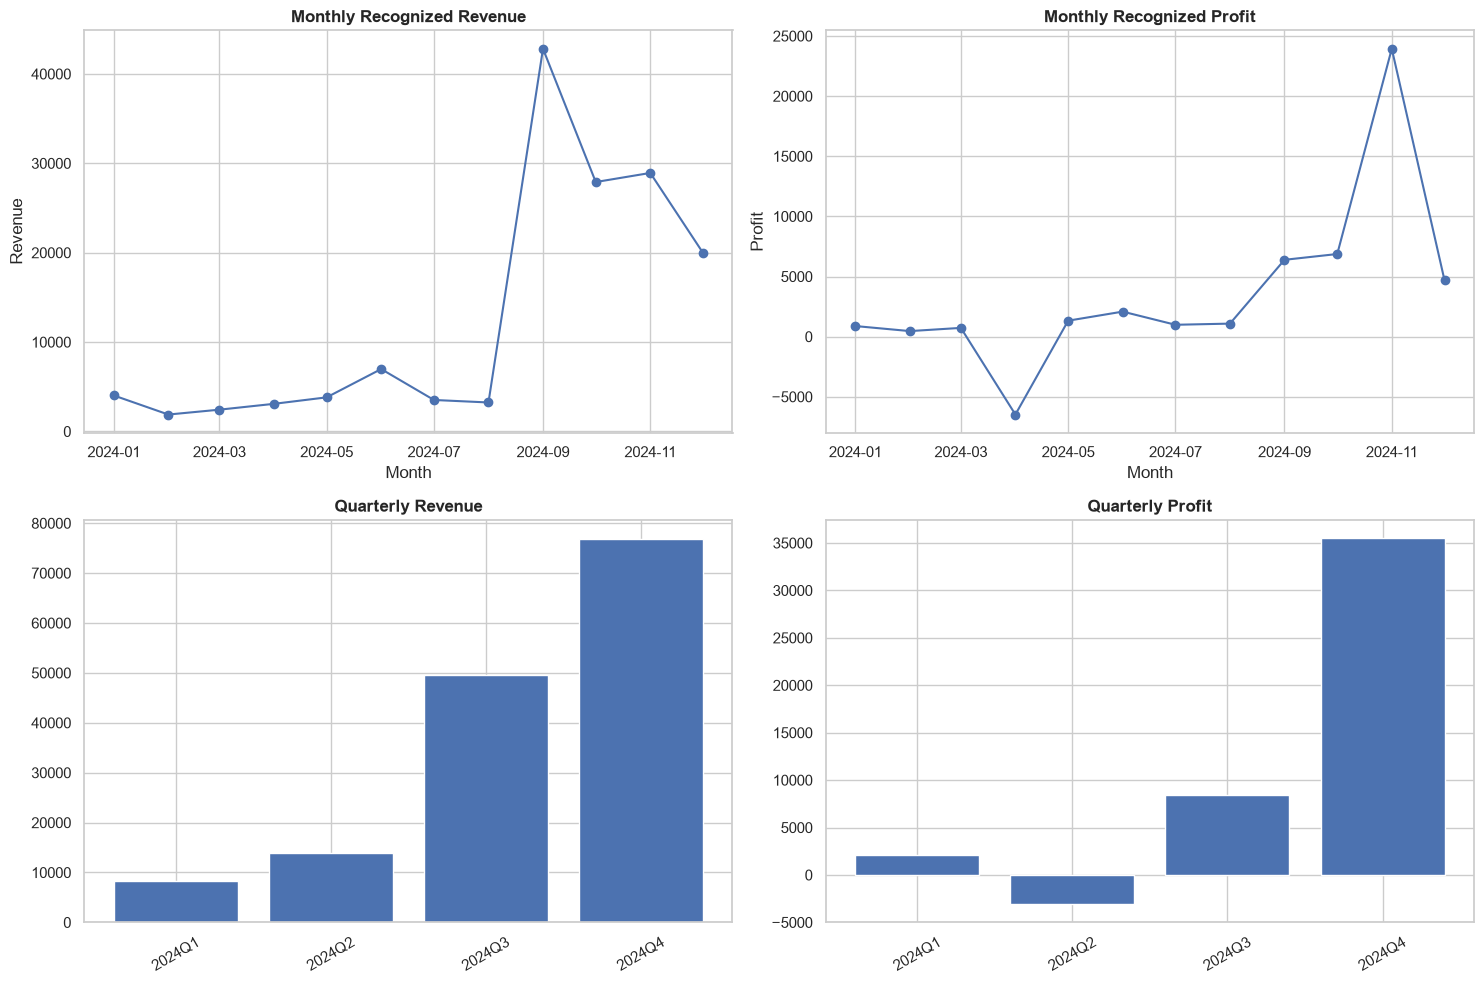

Highest revenue month: Sep 2024 (revenue 42,815.06)
Highest revenue quarter: 2024Q4 (revenue 76,796.27)


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0, 0].plot(monthly["Order_Date"], monthly["Revenue"], marker="o")
axes[0, 0].set_title("Monthly Recognized Revenue")
axes[0, 0].set_xlabel("Month"); axes[0, 0].set_ylabel("Revenue")
axes[0, 1].plot(monthly["Order_Date"], monthly["Profit"], marker="o")
axes[0, 1].set_title("Monthly Recognized Profit")
axes[0, 1].set_xlabel("Month"); axes[0, 1].set_ylabel("Profit")
axes[1, 0].bar(quarterly["Quarter"], quarterly["Revenue"])
axes[1, 0].set_title("Quarterly Revenue")
axes[1, 0].tick_params(axis="x", rotation=30)
axes[1, 1].bar(quarterly["Quarter"], quarterly["Profit"])
axes[1, 1].set_title("Quarterly Profit")
axes[1, 1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

if not monthly.empty:
    best_month = monthly.loc[monthly["Revenue"].idxmax()]
    print(f"Highest revenue month: {best_month['Month']} (revenue {best_month['Revenue']:,.2f})")
if not quarterly.empty:
    best_quarter = quarterly.loc[quarterly["Revenue"].idxmax()]
    print(f"Highest revenue quarter: {best_quarter['Quarter']} (revenue {best_quarter['Revenue']:,.2f})")


In [15]:
recognized = fact.loc[fact["Is_Recognized"]].copy()

product_perf = (recognized.groupby(
    ["Product_ID", "Product_Name", "Category", "Brand"], dropna=False
).agg(
    Revenue=("Recognized_Revenue", "sum"),
    Profit=("Recognized_Profit", "sum"),
    Units=("Recognized_Quantity", "sum"),
    Orders=("Order_ID", "nunique")
).reset_index())

product_perf["Profit_Margin_%"] = np.where(
    product_perf["Revenue"].ne(0),
    product_perf["Profit"] / product_perf["Revenue"] * 100, np.nan
)
product_perf["Revenue_Contribution_%"] = (
    product_perf["Revenue"] / product_perf["Revenue"].sum() * 100
)

top_revenue = product_perf.nlargest(10, "Revenue")
top_units = product_perf.nlargest(10, "Units")
top_profit = product_perf.nlargest(10, "Profit")
bottom_revenue = product_perf.nsmallest(10, "Revenue")

category_perf = (recognized.groupby("Category", dropna=False)
                 .agg(Revenue=("Recognized_Revenue", "sum"),
                      Profit=("Recognized_Profit", "sum"),
                      Units=("Recognized_Quantity", "sum"),
                      Orders=("Order_ID", "nunique"))
                 .reset_index())
category_perf["Profit_Margin_%"] = (
    category_perf["Profit"] / category_perf["Revenue"] * 100
)

brand_perf = (recognized.groupby("Brand", dropna=False)
              .agg(Revenue=("Recognized_Revenue", "sum"),
                   Profit=("Recognized_Profit", "sum"),
                   Units=("Recognized_Quantity", "sum"))
              .reset_index())
brand_perf["Profit_Margin_%"] = brand_perf["Profit"] / brand_perf["Revenue"] * 100

print("Top 10 products by revenue")
display(top_revenue.sort_values("Revenue", ascending=False).round(2))
print("Top 10 products by units")
display(top_units.sort_values("Units", ascending=False).round(2))
print("Top 10 products by profit")
display(top_profit.sort_values("Profit", ascending=False).round(2))
print("Bottom 10 products by revenue")
display(bottom_revenue.sort_values("Revenue").round(2))
print("Category performance")
display(category_perf.sort_values("Revenue", ascending=False).round(2))
print("Brand performance")
display(brand_perf.sort_values("Revenue", ascending=False).round(2))


Top 10 products by revenue


,Product_ID,Product_Name,Category,Brand,Revenue,Profit,Units,Orders,Profit_Margin_%,Revenue_Contribution_%
20,P018,Basmati Rice 5Kg,Cooking Essentials,Goldharvest,48261.23,6838.72,6575,25,14.17,32.48
17,P015,Salted Peanuts 200G,Snacks,Nuthouse,32715.02,9056.42,22532,23,27.68,22.02
24,P022,Toothpaste 150G,Personal Care,Brightsmile,27173.03,22548.88,4021,28,82.98,18.29
22,P020,Shampoo 340Ml,Personal Care,Silkycare,8765.68,3006.08,2618,25,34.29,5.9
7,P005,Choco Cream Biscuits,Biscuits,Crunchtime,5481.21,1603.91,6685,26,29.26,3.69
13,P011,Full Cream Milk 1L,Dairy,Purefarm,3699.92,548.87,3001,18,14.83,2.49
14,P012,Cheddar Cheese 200G,Dairy,Purefarm,3145.29,698.09,1064,18,22.19,2.12
9,P007,Digestive Biscuits,Biscuits,Goldenoat,2990.93,981.65,2184,17,32.82,2.01
19,P017,Soybean Oil 1L,Cooking Essentials,Goldharvest,2112.77,286.77,913,18,13.57,1.42
4,P002,Orange Juice 1L,Beverages,Freshfizz,1927.93,441.68,1189,14,22.91,1.3


Top 10 products by units


,Product_ID,Product_Name,Category,Brand,Revenue,Profit,Units,Orders,Profit_Margin_%,Revenue_Contribution_%
17,P015,Salted Peanuts 200G,Snacks,Nuthouse,32715.02,9056.42,22532,23,27.68,22.02
6,P004,Energy Drink 250Ml,Beverages,Voltup,1081.04,-6984.46,10754,21,-646.08,0.73
7,P005,Choco Cream Biscuits,Biscuits,Crunchtime,5481.21,1603.91,6685,26,29.26,3.69
20,P018,Basmati Rice 5Kg,Cooking Essentials,Goldharvest,48261.23,6838.72,6575,25,14.17,32.48
24,P022,Toothpaste 150G,Personal Care,Brightsmile,27173.03,22548.88,4021,28,82.98,18.29
21,P019,Iodized Salt 1Kg,Cooking Essentials,Saltco,1103.85,378.51,3297,23,34.29,0.74
13,P011,Full Cream Milk 1L,Dairy,Purefarm,3699.92,548.87,3001,18,14.83,2.49
22,P020,Shampoo 340Ml,Personal Care,Silkycare,8765.68,3006.08,2618,25,34.29,5.9
9,P007,Digestive Biscuits,Biscuits,Goldenoat,2990.93,981.65,2184,17,32.82,2.01
15,P013,Fruit Yogurt 150G,Dairy,Dairyjoy,1440.22,420.52,1854,19,29.20,0.97


Top 10 products by profit


,Product_ID,Product_Name,Category,Brand,Revenue,Profit,Units,Orders,Profit_Margin_%,Revenue_Contribution_%
24,P022,Toothpaste 150G,Personal Care,Brightsmile,27173.03,22548.88,4021,28,82.98,18.29
17,P015,Salted Peanuts 200G,Snacks,Nuthouse,32715.02,9056.42,22532,23,27.68,22.02
20,P018,Basmati Rice 5Kg,Cooking Essentials,Goldharvest,48261.23,6838.72,6575,25,14.17,32.48
22,P020,Shampoo 340Ml,Personal Care,Silkycare,8765.68,3006.08,2618,25,34.29,5.9
7,P005,Choco Cream Biscuits,Biscuits,Crunchtime,5481.21,1603.91,6685,26,29.26,3.69
9,P007,Digestive Biscuits,Biscuits,Goldenoat,2990.93,981.65,2184,17,32.82,2.01
14,P012,Cheddar Cheese 200G,Dairy,Purefarm,3145.29,698.09,1064,18,22.19,2.12
10,P008,Chicken Instant Noodles,Noodles,Quickbowl,1017.34,572.14,1684,19,56.24,0.68
13,P011,Full Cream Milk 1L,Dairy,Purefarm,3699.92,548.87,3001,18,14.83,2.49
8,P006,Butter Cookies,Biscuits,Crunchtime,1674.63,506.47,1192,23,30.24,1.13


... (2 outputs left out)

Category performance


,Category,Revenue,Profit,Units,Orders,Profit_Margin_%
2,Cooking Essentials,51477.84,7504.0,10785,66,14.58
5,Personal Care,37301.98,26071.73,8213,77,69.89
6,Snacks,34732.42,9791.25,24712,57,28.19
1,Biscuits,10200.92,3108.94,10099,67,30.48
3,Dairy,8344.72,1676.37,5967,56,20.09
0,Beverages,3920.04,-6155.81,13448,66,-157.03
4,Noodles,2624.34,944.64,3972,58,36.0


Brand performance


,Brand,Revenue,Profit,Units,Profit_Margin_%
8,Goldharvest,50373.99,7125.49,7488,14.15
10,Nuthouse,32715.02,9056.42,22532,27.68
2,Brightsmile,27173.03,22548.88,4021,82.98
14,Silkycare,9682.07,3351.97,3952,34.62
4,Crunchtime,7209.99,2127.29,7915,29.5
11,Purefarm,6904.49,1255.84,4113,18.19
7,Goldenoat,2990.93,981.65,2184,32.82
6,Freshfizz,2719.4,703.05,2034,25.85
3,Crispybite,1986.71,725.99,2161,36.54
12,Quickbowl,1443.85,703.75,2667,48.74


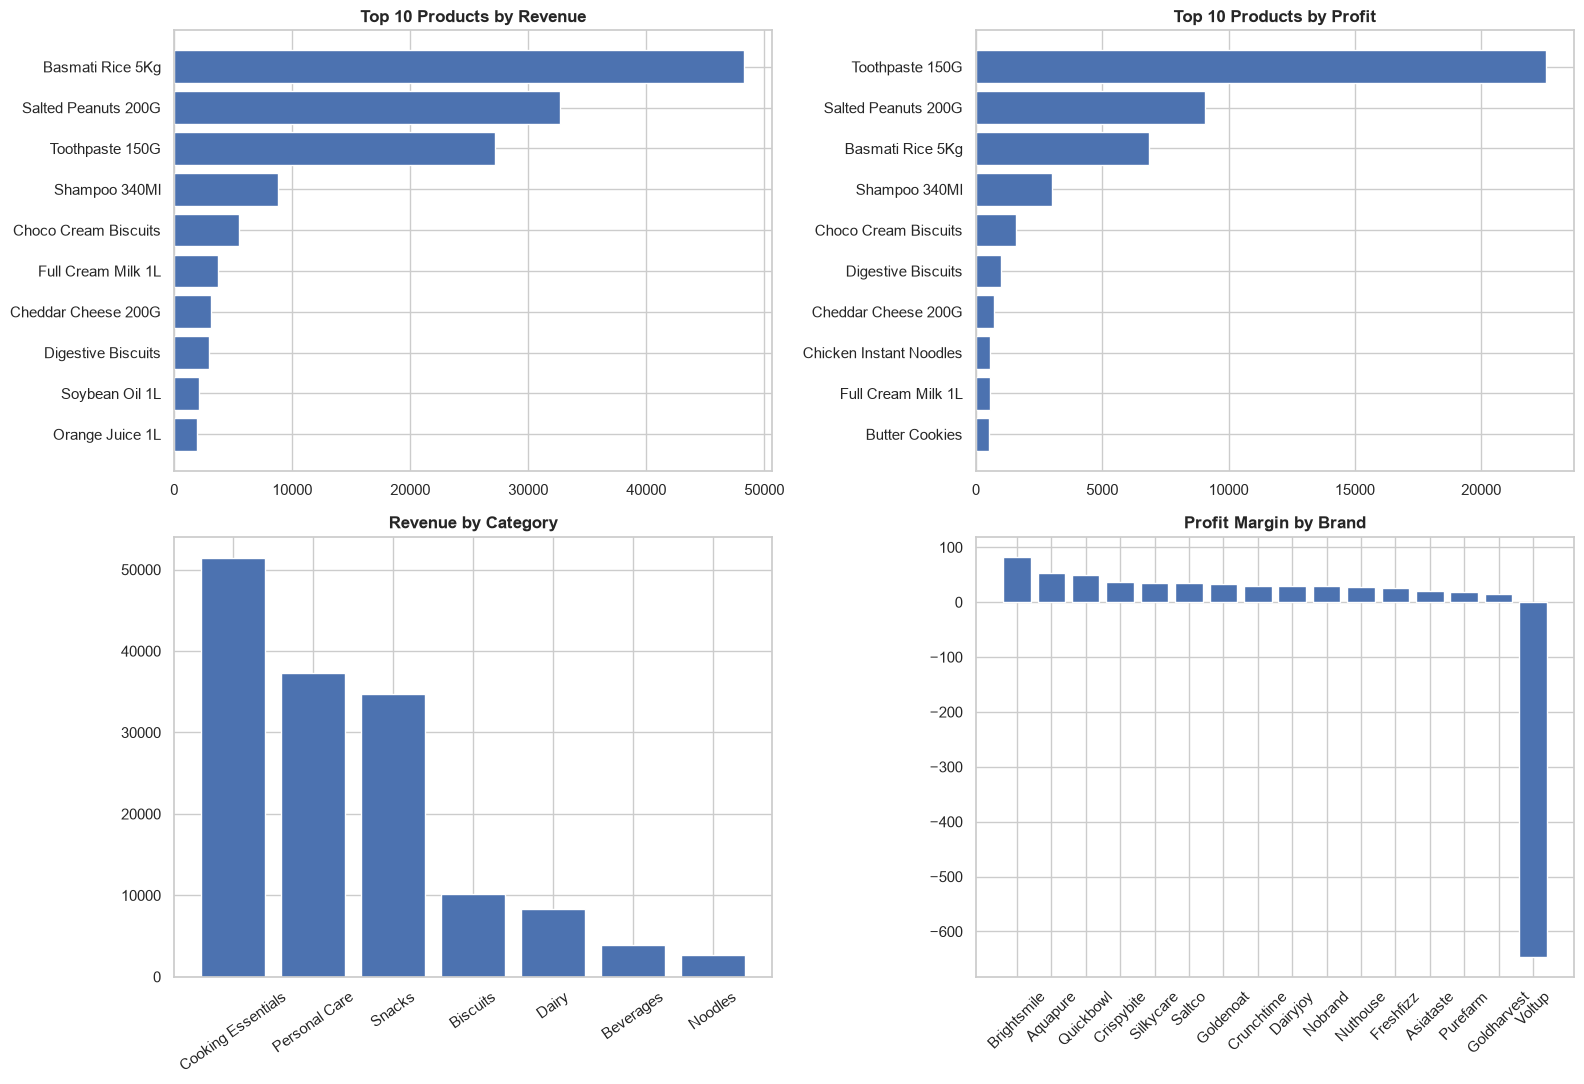

Revenue leader: Basmati Rice 5Kg (48,261.23)
Profit leader: Toothpaste 150G (22,548.88)
Products with negative recognized profit: 1


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
d = top_revenue.sort_values("Revenue")
axes[0, 0].barh(d["Product_Name"], d["Revenue"])
axes[0, 0].set_title("Top 10 Products by Revenue")
d = top_profit.sort_values("Profit")
axes[0, 1].barh(d["Product_Name"], d["Profit"])
axes[0, 1].set_title("Top 10 Products by Profit")
d = category_perf.sort_values("Revenue", ascending=False)
axes[1, 0].bar(d["Category"], d["Revenue"])
axes[1, 0].set_title("Revenue by Category")
axes[1, 0].tick_params(axis="x", rotation=35)
d = brand_perf.sort_values("Profit_Margin_%", ascending=False)
axes[1, 1].bar(d["Brand"], d["Profit_Margin_%"])
axes[1, 1].set_title("Profit Margin by Brand")
axes[1, 1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

if not product_perf.empty:
    p1 = product_perf.loc[product_perf["Revenue"].idxmax()]
    p2 = product_perf.loc[product_perf["Profit"].idxmax()]
    print(f"Revenue leader: {p1['Product_Name']} ({p1['Revenue']:,.2f})")
    print(f"Profit leader: {p2['Product_Name']} ({p2['Profit']:,.2f})")
print("Products with negative recognized profit:", int((product_perf["Profit"] < 0).sum()))


In [17]:
region_perf = (fact.groupby("Region", dropna=False)
               .agg(Revenue=("Recognized_Revenue", "sum"),
                    Profit=("Recognized_Profit", "sum"),
                    Units=("Recognized_Quantity", "sum"),
                    Orders=("Order_ID", "nunique"))
               .reset_index())
region_perf["AOV"] = np.where(region_perf["Orders"] > 0,
                              region_perf["Revenue"] / region_perf["Orders"], np.nan)
region_perf["Profit_Margin_%"] = np.where(
    region_perf["Revenue"] > 0,
    region_perf["Profit"] / region_perf["Revenue"] * 100, np.nan
)

city_perf = (fact.groupby(["Region", "City"], dropna=False)
             .agg(Revenue=("Recognized_Revenue", "sum"),
                  Profit=("Recognized_Profit", "sum"),
                  Units=("Recognized_Quantity", "sum"),
                  Orders=("Order_ID", "nunique"))
             .reset_index()
             .sort_values("Revenue", ascending=False))

# Return rate by geography: order-level flags avoid counting multiple lines as multiple returned orders.
order_geo = (fact.groupby(["Order_ID", "Region", "City"], dropna=False)
             .agg(Is_Returned=("Is_Returned", "max"),
                  Is_Cancelled=("Is_Cancelled", "max"))
             .reset_index())
geo_returns = (order_geo.groupby("Region", dropna=False)
               .agg(Total_Orders=("Order_ID", "nunique"),
                    Returned_Orders=("Is_Returned", "sum"))
               .reset_index())
geo_returns["Return_Rate_%"] = (
    geo_returns["Returned_Orders"] / geo_returns["Total_Orders"] * 100
)

print("Regional performance")
display(region_perf.sort_values("Revenue", ascending=False).round(2))
print("Top 15 cities by revenue")
display(city_perf.head(15).round(2))
print("Return rate by region")
display(geo_returns.sort_values("Return_Rate_%", ascending=False).round(2))


Regional performance


,Region,Revenue,Profit,Units,Orders,AOV,Profit_Margin_%
3,West,50223.65,452.22,25140,144,348.78,0.90
2,South,39956.97,27629.03,13561,168,237.84,69.15
0,East,33580.95,9076.0,23032,98,342.66,27.03
1,North,24840.68,5783.86,15463,185,134.27,23.28


Top 15 cities by revenue


,Region,City,Revenue,Profit,Units,Orders
38,West,Mumbai,40620.21,6499.3,7369,53
23,South,Bengaluru,24789.62,22743.72,2880,26
9,East,Patna,16035.4,4950.46,10430,23
2,East,Bhubaneswar,14894.64,3363.65,10691,35
16,North,Delhi,9154.29,2044.13,5471,60
19,North,Lucknow,9028.71,1912.16,6350,24
24,South,Chennai,6925.72,2167.67,4849,49
32,West,Ahmedabad,5966.82,-6977.84,15855,62
26,South,Hyderabad,4740.09,1490.54,3864,69
14,North,Chandigarh,4168.99,1184.23,2399,61


Return rate by region


,Region,Total_Orders,Returned_Orders,Return_Rate_%
3,West,144,12,8.33
2,South,168,10,5.95
1,North,185,9,4.86
0,East,98,3,3.06


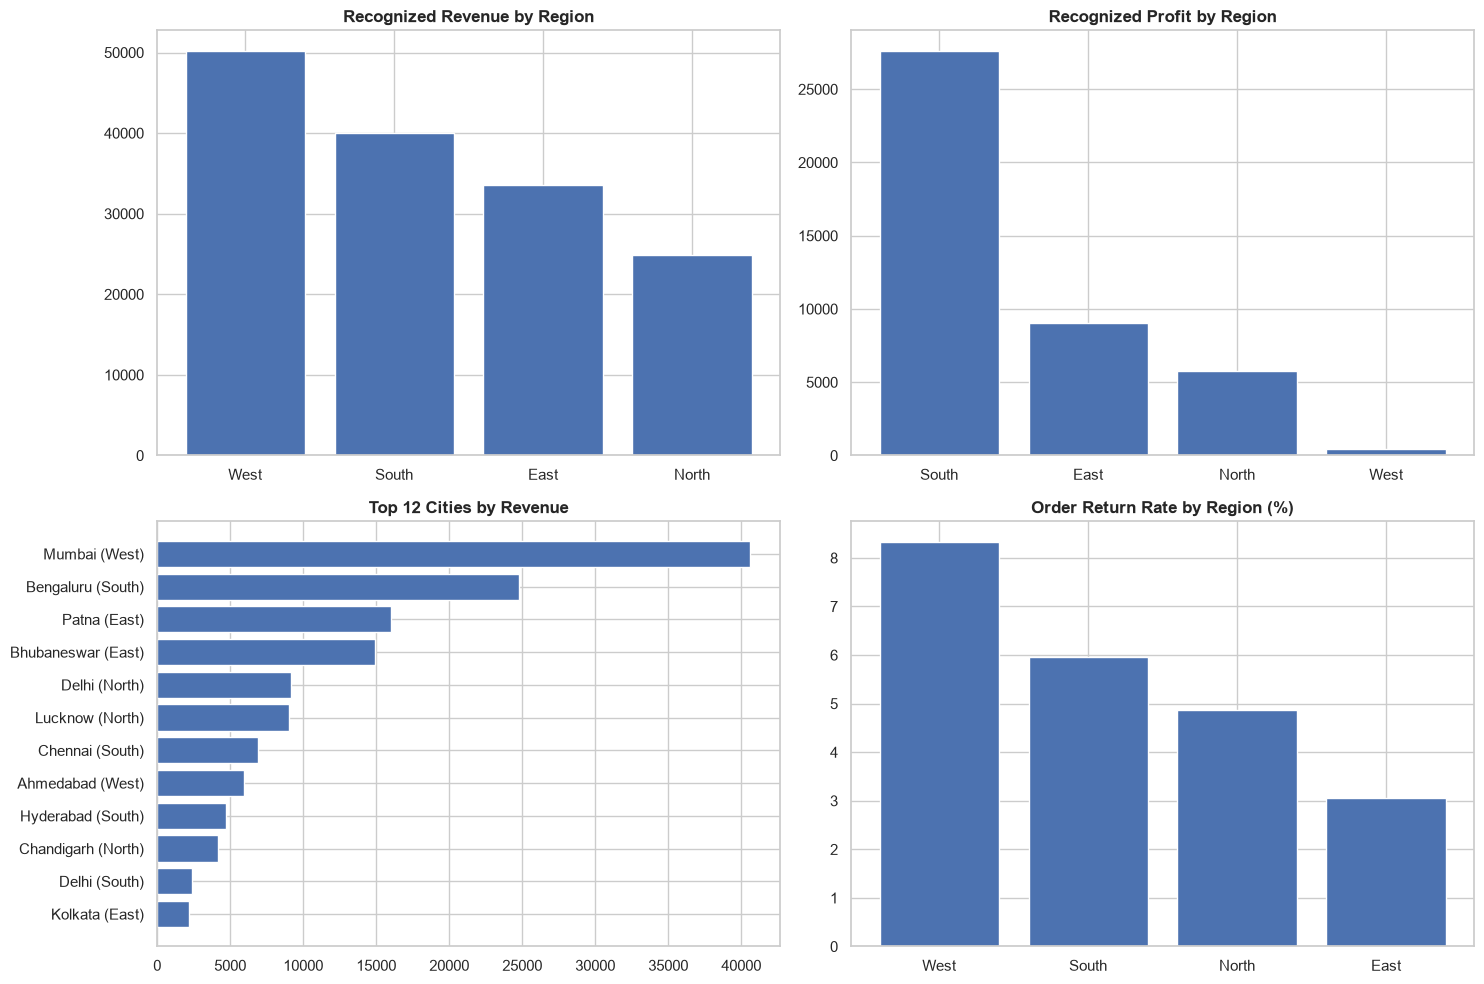

Highest-revenue region: West (50,223.65)
Highest-revenue city: Mumbai, West (40,620.21)


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
d = region_perf.sort_values("Revenue", ascending=False)
axes[0, 0].bar(d["Region"].astype(str), d["Revenue"])
axes[0, 0].set_title("Recognized Revenue by Region")
d = region_perf.sort_values("Profit", ascending=False)
axes[0, 1].bar(d["Region"].astype(str), d["Profit"])
axes[0, 1].set_title("Recognized Profit by Region")
d = city_perf.head(12).sort_values("Revenue")
axes[1, 0].barh(d["City"].astype(str) + " (" + d["Region"].astype(str) + ")", d["Revenue"])
axes[1, 0].set_title("Top 12 Cities by Revenue")
d = geo_returns.sort_values("Return_Rate_%", ascending=False)
axes[1, 1].bar(d["Region"].astype(str), d["Return_Rate_%"])
axes[1, 1].set_title("Order Return Rate by Region (%)")
plt.tight_layout()
plt.show()

if not region_perf.empty:
    r = region_perf.loc[region_perf["Revenue"].idxmax()]
    print(f"Highest-revenue region: {r['Region']} ({r['Revenue']:,.2f})")
if not city_perf.empty:
    c = city_perf.iloc[0]
    print(f"Highest-revenue city: {c['City']}, {c['Region']} ({c['Revenue']:,.2f})")


In [19]:
# Customer-level value and repeat-purchase metrics.
customer_perf = (recognized.groupby("Customer_ID", dropna=False)
                 .agg(
                     Revenue=("Recognized_Revenue", "sum"),
                     Profit=("Recognized_Profit", "sum"),
                     Orders=("Order_ID", "nunique"),
                     Units=("Recognized_Quantity", "sum"),
                     Last_Purchase=("Order_Date", "max"),
                     First_Purchase=("Order_Date", "min")
                 ).reset_index())

customer_perf["AOV"] = np.where(
    customer_perf["Orders"] > 0,
    customer_perf["Revenue"] / customer_perf["Orders"], np.nan
)
customer_perf["Repeat_Customer_Flag"] = customer_perf["Orders"] >= 2

customer_perf = customer_perf.merge(
    customers[["Customer_ID", "Customer_Name", "Customer_Type", "Loyalty_Tier"]],
    on="Customer_ID", how="left", validate="one_to_one"
)

customer_type_perf = (customer_perf.groupby("Customer_Type", dropna=False)
                      .agg(Customers=("Customer_ID", "nunique"),
                           Revenue=("Revenue", "sum"),
                           Profit=("Profit", "sum"),
                           Orders=("Orders", "sum"))
                      .reset_index())
customer_type_perf["Revenue_Per_Customer"] = (
    customer_type_perf["Revenue"] / customer_type_perf["Customers"]
)

loyalty_perf = (customer_perf.groupby("Loyalty_Tier", dropna=False)
                .agg(Customers=("Customer_ID", "nunique"),
                     Revenue=("Revenue", "sum"),
                     Profit=("Profit", "sum"),
                     Orders=("Orders", "sum"))
                .reset_index())
loyalty_perf["Revenue_Per_Customer"] = (
    loyalty_perf["Revenue"] / loyalty_perf["Customers"]
)

repeat_summary = pd.DataFrame({
    "Metric": ["Recognized customers", "Repeat customers (2+ orders)",
               "Repeat customer rate (%)", "Average orders per customer",
               "Average customer revenue"],
    "Value": [
        customer_perf["Customer_ID"].nunique(),
        customer_perf.loc[customer_perf["Repeat_Customer_Flag"], "Customer_ID"].nunique(),
        customer_perf["Repeat_Customer_Flag"].mean() * 100,
        customer_perf["Orders"].mean(),
        customer_perf["Revenue"].mean()
    ]
})

print("Customer type performance")
display(customer_type_perf.sort_values("Revenue", ascending=False).round(2))
print("Loyalty tier performance")
display(loyalty_perf.sort_values("Revenue", ascending=False).round(2))
print("Repeat purchase summary")
display(repeat_summary.round(2))
print("Top 15 customers by recognized revenue")
display(customer_perf.nlargest(15, "Revenue").round(2))


Customer type performance


,Customer_Type,Customers,Revenue,Profit,Orders,Revenue_Per_Customer
3,Supermarket,16,46795.41,20997.21,121,2924.71
0,Convenience Store,9,43744.46,7147.13,73,4860.5
1,E-Commerce,8,33326.39,9094.0,53,4165.8
4,Wholesaler,13,13008.7,3878.0,74,1000.67
5,<NA>,2,7607.26,1067.33,32,3803.63
2,Retail Store,14,4120.04,757.45,94,294.29


Loyalty tier performance


,Loyalty_Tier,Customers,Revenue,Profit,Orders,Revenue_Per_Customer
1,Gold,15,65731.06,14410.22,97,4382.07
2,Platinum,10,46634.79,28128.5,77,4663.48
0,Bronze,21,18762.9,4133.32,151,893.47
3,Silver,14,9866.23,-4798.27,90,704.73
4,<NA>,2,7607.26,1067.33,32,3803.63


Repeat purchase summary


,Metric,Value
0,Recognized customers,62.00
1,Repeat customers (2+ orders),59.00
2,Repeat customer rate (%),95.24
3,Average orders per customer,7.10
4,Average customer revenue,2358.77


Top 15 customers by recognized revenue


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17104\102489793.py:63: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(customer_perf.nlargest(15, "Revenue").round(2))


,Customer_ID,Revenue,Profit,Orders,Units,Last_Purchase,First_Purchase,AOV,Repeat_Customer_Flag,Customer_Name,Customer_Type,Loyalty_Tier
42,C042,39196.14,6111.69,10,6352,2024-12-04,2024-01-01,3919.61,True,Customer 042,Convenience Store,Gold
28,C028,23297.52,22415.12,8,1512,2024-11-19,2024-04-23,2912.19,True,Customer 028,Supermarket,Platinum
8,C008,15380.11,4750.68,4,10058,2024-10-18,2024-01-01,3845.03,True,Customer 008,E-Commerce,Gold
16,C016,13840.85,3172.49,10,10225,2024-12-31,2024-04-04,1384.08,True,Customer 016,E-Commerce,Platinum
62,<NA>,7460.06,1013.63,30,8401,2024-12-30,2024-01-02,248.67,True,NaN,<NA>,<NA>
3,C003,6759.03,1184.77,15,2299,2024-12-26,2024-01-04,450.60,True,Customer 003,Supermarket,Bronze
39,C039,4297.54,1515.74,11,2352,2024-12-22,2024-03-28,390.69,True,Customer 039,Supermarket,Gold
44,C044,2388.96,-6711.09,8,12003,2024-10-19,2024-01-03,298.62,True,Customer 044,Supermarket,Silver
15,C015,2139.49,728.12,6,775,2024-12-08,2024-07-21,356.58,True,Customer 015,Wholesaler,Gold
56,C056,2098.26,378.66,4,504,2024-12-22,2024-04-17,524.57,True,Customer 056,Supermarket,Silver


In [20]:
# RFM scoring. Rank first so qcut can work even when values have tied quantiles.
rfm = customer_perf[["Customer_ID", "Last_Purchase", "Orders", "Revenue"]].copy()
analysis_date = recognized["Order_Date"].max() + pd.Timedelta(days=1)
rfm["Recency_Days"] = (analysis_date - rfm["Last_Purchase"]).dt.days

def quantile_score(series, higher_is_better=True):
    ranks = series.rank(method="first", ascending=True)
    scores = pd.qcut(ranks, q=4, labels=[1, 2, 3, 4]).astype(int)
    return scores if higher_is_better else 5 - scores

rfm["R_Score"] = quantile_score(rfm["Recency_Days"], higher_is_better=False)
rfm["F_Score"] = quantile_score(rfm["Orders"], higher_is_better=True)
rfm["M_Score"] = quantile_score(rfm["Revenue"], higher_is_better=True)
rfm["RFM_Score"] = rfm[["R_Score", "F_Score", "M_Score"]].sum(axis=1)

def rfm_segment(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Champions"
    if row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Loyal Customers"
    if row["R_Score"] >= 3 and row["F_Score"] <= 2:
        return "New / Potential Loyalists"
    if row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At-Risk Loyal Customers"
    return "Hibernating / Low Value"

rfm["RFM_Segment"] = rfm.apply(rfm_segment, axis=1)
rfm = rfm.merge(
    customers[["Customer_ID", "Customer_Name", "Customer_Type", "Loyalty_Tier"]],
    on="Customer_ID", how="left", validate="one_to_one"
)

rfm_summary = (rfm.groupby("RFM_Segment", dropna=False)
               .agg(Customers=("Customer_ID", "nunique"),
                    Revenue=("Revenue", "sum"),
                    Avg_Orders=("Orders", "mean"),
                    Avg_Recency_Days=("Recency_Days", "mean"))
               .reset_index()
               .sort_values("Customers", ascending=False))

display(rfm.sort_values("RFM_Score", ascending=False).head(20))
display(rfm_summary.round(2))


,Customer_ID,Last_Purchase,Orders,Revenue,Recency_Days,R_Score,F_Score,M_Score,RFM_Score,RFM_Segment,Customer_Name,Customer_Type,Loyalty_Tier
3,C003,2024-12-26,15,6759.032,6,4,4,4,12,Champions,Customer 003,Supermarket,Bronze
9,C009,2024-12-23,9,1622.266,9,4,4,4,12,Champions,Customer 009,Supermarket,Platinum
16,C016,2024-12-31,10,13840.85,1,4,4,4,12,Champions,Customer 016,E-Commerce,Platinum
62,<NA>,2024-12-30,30,7460.0625,2,4,4,4,12,Champions,NaN,<NA>,<NA>
39,C039,2024-12-22,11,4297.544,10,4,4,4,12,Champions,Customer 039,Supermarket,Gold
4,C004,2024-12-23,8,1961.424,9,4,3,4,11,Champions,Customer 004,Wholesaler,Platinum
43,C043,2024-12-15,11,1749.095,17,3,4,4,11,Champions,Customer 043,Convenience Store,Bronze
42,C042,2024-12-04,10,39196.14,28,3,4,4,11,Champions,Customer 042,Convenience Store,Gold
50,C050,2024-12-30,11,605.959,2,4,4,3,11,Champions,Customer 050,Convenience Store,Platinum
59,C059,2024-12-18,9,356.963,14,4,4,2,10,Hibernating / Low Value,Customer 059,Supermarket,Bronze


,RFM_Segment,Customers,Revenue,Avg_Orders,Avg_Recency_Days
2,Hibernating / Low Value,30,28134.84,5.80,54.57
4,New / Potential Loyalists,11,10623.26,4.73,17.27
1,Champions,11,79754.37,11.42,9.67
0,At-Risk Loyal Customers,5,1726.36,8.60,67.40
3,Loyal Customers,5,28363.42,8.20,48.40


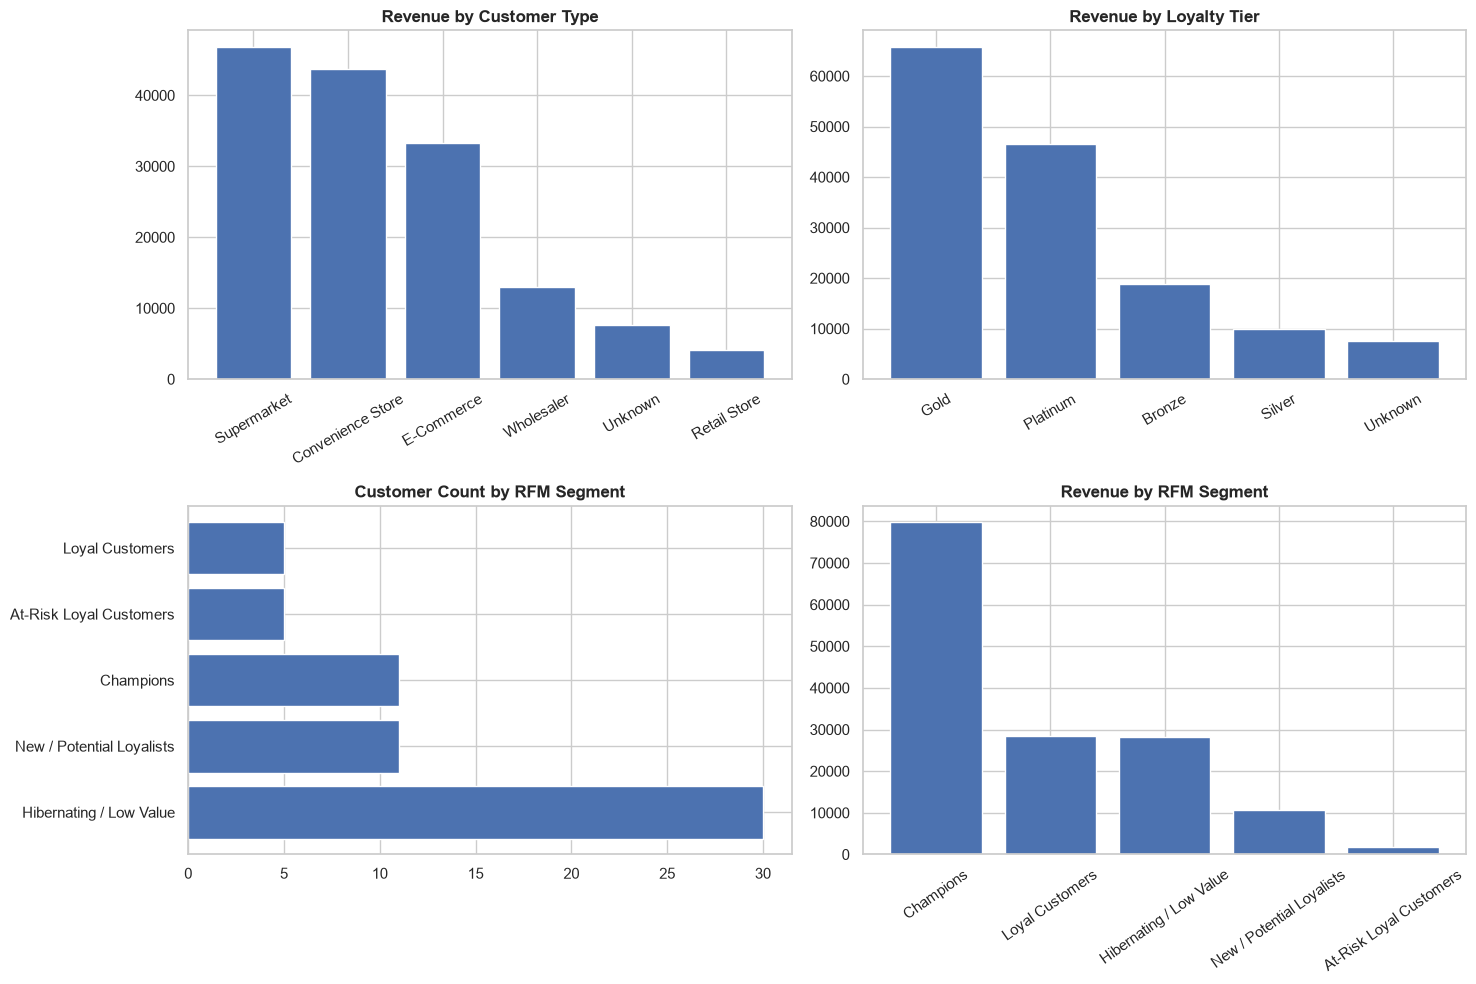

In [22]:
# Customer analysis charts (robust to missing or mixed-type category labels).

def clean_chart_labels(series):
    # Convert every label to a real Python string; replace missing labels with Unknown.
    return series.astype("object").where(series.notna(), "Unknown").map(str).tolist()

def clean_chart_values(series):
    # Ensure bar heights are numeric and missing values do not break the chart.
    return pd.to_numeric(series, errors="coerce").fillna(0).tolist()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

d = customer_type_perf.sort_values("Revenue", ascending=False)
axes[0, 0].bar(clean_chart_labels(d["Customer_Type"]), clean_chart_values(d["Revenue"]))
axes[0, 0].set_title("Revenue by Customer Type")
axes[0, 0].tick_params(axis="x", rotation=30)

d = loyalty_perf.sort_values("Revenue", ascending=False)
axes[0, 1].bar(clean_chart_labels(d["Loyalty_Tier"]), clean_chart_values(d["Revenue"]))
axes[0, 1].set_title("Revenue by Loyalty Tier")
axes[0, 1].tick_params(axis="x", rotation=30)

axes[1, 0].barh(clean_chart_labels(rfm_summary["RFM_Segment"]), clean_chart_values(rfm_summary["Customers"]))
axes[1, 0].set_title("Customer Count by RFM Segment")

d = rfm_summary.sort_values("Revenue", ascending=False)
axes[1, 1].bar(clean_chart_labels(d["RFM_Segment"]), clean_chart_values(d["Revenue"]))
axes[1, 1].set_title("Revenue by RFM Segment")
axes[1, 1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [ ]:
print("===== BUSINESS OBSERVATIONS =====")
print(f"Recognized revenue: {total_revenue:,.2f}")
print(f"Recognized gross profit: {total_profit:,.2f}")
print(f"Overall profit margin: {profit_margin:.2f}%")
print(f"Delivered recognized orders: {total_orders:,}")
print(f"Recognized units sold: {total_units:,.0f}")
print(f"Average order value: {aov:,.2f}")

if not category_perf.empty:
    x = category_perf.loc[category_perf["Revenue"].idxmax()]
    print(f"Top revenue category: {x['Category']} ({x['Revenue']:,.2f})")
if not brand_perf.empty:
    x = brand_perf.loc[brand_perf["Profit_Margin_%"].idxmax()]
    print(f"Highest-margin brand: {x['Brand']} ({x['Profit_Margin_%']:.2f}%)")
if not region_perf.empty:
    x = region_perf.loc[region_perf["Revenue"].idxmax()]
    print(f"Top revenue region: {x['Region']} ({x['Revenue']:,.2f})")
if not customer_type_perf.empty:
    x = customer_type_perf.loc[customer_type_perf["Revenue"].idxmax()]
    print(f"Top customer type by revenue: {x['Customer_Type']} ({x['Revenue']:,.2f})")
if not rfm_summary.empty:
    x = rfm_summary.loc[rfm_summary["Customers"].idxmax()]
    print(f"Largest RFM segment: {x['RFM_Segment']} ({int(x['Customers'])} customers)")

print("\\nInterpretation checklist:")
print("- Compare revenue leaders with profit-margin leaders; high revenue does not always mean high profitability.")
print("- Investigate regions/cities with high return rates before increasing marketing or distribution spend.")
print("- Use RFM segments to design retention campaigns; validate segment sizes before taking action.")
print("- Treat missing customer IDs and unmatched product/customer keys as data-quality limitations.")


In [23]:
OUTPUT_FILE = "FMCG_EDA_1_to_4_Analysis_Results.xlsx"

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    sales_kpis.to_excel(writer, sheet_name="Sales_KPIs", index=False)
    monthly.to_excel(writer, sheet_name="Monthly_Trend", index=False)
    quarterly.to_excel(writer, sheet_name="Quarterly_Trend", index=False)
    yearly.to_excel(writer, sheet_name="Yearly_Trend", index=False)
    product_perf.to_excel(writer, sheet_name="Product_Performance", index=False)
    category_perf.to_excel(writer, sheet_name="Category_Performance", index=False)
    brand_perf.to_excel(writer, sheet_name="Brand_Performance", index=False)
    region_perf.to_excel(writer, sheet_name="Region_Performance", index=False)
    city_perf.to_excel(writer, sheet_name="City_Performance", index=False)
    geo_returns.to_excel(writer, sheet_name="Regional_Returns", index=False)
    customer_perf.to_excel(writer, sheet_name="Customer_Performance", index=False)
    customer_type_perf.to_excel(writer, sheet_name="Customer_Type", index=False)
    loyalty_perf.to_excel(writer, sheet_name="Loyalty_Tier", index=False)
    rfm.to_excel(writer, sheet_name="RFM_Segmentation", index=False)
    rfm_summary.to_excel(writer, sheet_name="RFM_Summary", index=False)
    quality_summary.to_excel(writer, sheet_name="Data_Quality", index=False)
    fact.to_excel(writer, sheet_name="Analysis_Fact", index=False)

print(f"Export complete: {OUTPUT_FILE}")


Export complete: FMCG_EDA_1_to_4_Analysis_Results.xlsx
